# Мастер-файл всех работ по Python (GitHub: RendWanProys)

Единый ноутбук объединяет все Python-проекты и Jupyter-тетради из репозиториев:
`PyLab1`, `PyLab2`, `PY`, `Py3`, `Pandas`, `Py6`, `PyLab6-8`, `py7-8`.

Все исходные данные (`.csv`, `.txt`, `.npy`, `.pkl`, пакет `my_package`, папка `data/`) сохранены в соответствующих подпапках каталога `PythonWorks/`, а функция `use_project(...)` переключает рабочую директорию (`os.chdir`) перед выполнением каждого блока, чтобы относительные пути не ломались.


In [ ]:
import os
import sys
from pathlib import Path

def find_python_works_root() -> Path:
    cwd = Path.cwd().resolve()
    for candidate in [cwd, cwd / "PythonWorks", *cwd.parents]:
        if (candidate / "PyLab1").is_dir() and (candidate / "py7-8").is_dir():
            return candidate
        if (candidate / "PythonWorks" / "PyLab1").is_dir():
            return candidate / "PythonWorks"
    raise FileNotFoundError("Не найдена папка PythonWorks с проектами")

PYTHON_WORKS_ROOT = find_python_works_root()

def use_project(folder_name: str) -> Path:
    proj_dir = (PYTHON_WORKS_ROOT / folder_name).resolve()
    os.chdir(proj_dir)
    if str(proj_dir) not in sys.path:
        sys.path.insert(0, str(proj_dir))
    print(f"[cwd] -> {proj_dir}")
    return proj_dir

print("PYTHON_WORKS_ROOT:", PYTHON_WORKS_ROOT)


---
## 1. PyLab1 — Основы Python и NumPy (кортежи, матрицы, списки, множества, словари)
- Репозиторий: https://github.com/RendWanProys/PyLab1
- Локальная папка: `PythonWorks/PyLab1/`


In [ ]:
use_project("PyLab1")


### Файл `PyLab1/Main.py`


In [ ]:
import numpy as np


def task_1():
    print("1: Одномерные массивы. Кортеж")
    r_tuple = (12.5, 4.0, 15.2, 8.8, 20.0, 6.5, 12.0, 25.0)


    r_total_classic = sum(r_tuple)



    print(f"Сопротивления элементов цепи: {r_tuple}")
    print(f"Общее сопротивление (sum): {r_total_classic:.2f} Ом")

def task_2():
    print("2: Двумерные массивы")
    matrix = np.array([
        [5,  8, 12],
        [3,  7,  8],
        [14, 2,  9]
    ])
    print("Исходная матрица:")
    print(matrix)
    values, counts = np.unique(matrix, return_counts=True)
    has_one_pair = np.sum(counts == 2) == 1
    no_higher_repeats = np.all(counts <= 2)
    has_only_two = bool(has_one_pair and no_higher_repeats)

    if has_only_two:
        dup_val = values[counts == 2][0]
        print(f"Результат: Да. В массиве ровно два одинаковых элемента (число {dup_val} встречается 2 раза).")
    else:
        print("Результат: Нет. Условие не выполнено.")
    print(f"Ответ: {has_only_two}\n")

def task_3():
    print("3: Списки")
    a_list = [10, 25, 42, 7, 88, 19, 56, 33, 90]
    print(f"Исходный список: {a_list}")

    even_slice = a_list[::2]
    print(f"Элементы с четными индексами [::2]: {even_slice}")

    print("Вывод через пробел:", *even_slice, "\n")

def task_4():
    print("4: Множества")
    numbers = [1, 2, 3, 2, 1, 4, 5, 3, 7]
    print(f"Список чисел: {numbers}")

    distinct_set = set(numbers)
    count_distinct_set = len(distinct_set)


    print(f"Множество уникальных чисел (set): {distinct_set}")
    print(f"Количество различных чисел (len(set)): {count_distinct_set}")


def task_5():
    print("5: Словари")
    text = "one two one thr two"
    print(f"Исходная строка текста: '{text}'")

    words = text.split()
    counts = {}
    result = []

    for word in words:
        prev_count = counts.get(word, 0)
        result.append(prev_count)
        counts[word] = prev_count + 1

    print("Результат подсчета предшествующих вхождений:")
    print(" ".join(map(str, result)))
    print(f"Итоговый словарь частот: {counts}\n")


if __name__ == "__main__":

    print("Вариант 1")


    task_1()
    task_2()
    task_3()
    task_4()
    task_5()


---
## 2. PyLab2 — Объектно-ориентированное программирование (ООП)
- Репозиторий: https://github.com/RendWanProys/PyLab2
- Локальная папка: `PythonWorks/PyLab2/`


In [ ]:
use_project("PyLab2")


### Файл `PyLab2/OOP.py`


In [ ]:
import numpy as np


class Product:
    def __init__(self, price, quantity):
        self.price = float(price)
        self.quantity = int(quantity)

    def get_info(self):
        return f"Цена: {self.price}, Количество: {self.quantity}"

    def get_total_cost(self):
        return self.price * self.quantity


class Date:
    def __init__(self, day=1, month=1, year=2024):
        self.day = int(day)
        self.month = int(month)
        self.year = int(year)

    def __del__(self):
        pass

    def is_same_day_month(self):
        return self.day == self.month

    def add_month(self):
        if self.month == 12:
            self.month = 1
            self.year += 1
        else:
            self.month += 1

    def get_info(self):
        return f"{self.day:02d}.{self.month:02d}.{self.year}"


class ProductWithAge(Product):
    def __init__(self, price, quantity, year):
        super().__init__(price, quantity)
        self.year = int(year)

    def get_age(self, current_year=2024):
        return current_year - self.year

    def get_info(self):
        return f"{super().get_info()}, Год выпуска: {self.year}"


class Medicine(Date):
    def __init__(self, name, day, month, year, company):
        super().__init__(day, month, year)
        self.name = str(name)
        self.company = str(company)

    def __del__(self):
        pass

    def days_since_manufacture(self):
        m_date = np.datetime64(f"{self.year:04d}-{self.month:02d}-{self.day:02d}")
        today = np.datetime64("today")
        return int((today - m_date).astype(int))

    def get_info(self):
        return f"Лекарство: {self.name}, Фирма: {self.company}, Дата выпуска: {super().get_info()}"


class WarehouseProduct:
    def __init__(self, name, price, quantity):
        self.name = str(name)
        self.price = float(price)
        self.quantity = int(quantity)

    def quality(self):
        if self.quantity == 0:
            return 0.0
        return self.price / self.quantity

    def get_info(self):
        return f"Товар: {self.name}, Цена: {self.price}, Количество: {self.quantity}, Качество Q: {self.quality():.2f}"


class WarehouseProductWithYear(WarehouseProduct):
    def __init__(self, name, price, quantity, p):
        super().__init__(name, price, quantity)
        self.p = int(p)

    def quality(self, current_year=2024):
        if hasattr(current_year, "year"):
            current_year = current_year.year
        q = super().quality()
        return q + 0.5 * (int(current_year) - self.p)

    def get_info(self, current_year=2024):
        if hasattr(current_year, "year"):
            current_year = current_year.year
        return f"Товар: {self.name}, Цена: {self.price}, Количество: {self.quantity}, Год P: {self.p}, Качество Qp: {self.quality(current_year):.2f}"


def run_task1():
    print("--- Задание 1 ---")
    p1 = Product(150.5, 10)
    print(p1.get_info())
    print("Общая стоимость:", p1.get_total_cost())


def run_task2():
    print("\n--- Задание 2 ---")
    d_const = Date(12, 12, 2026)
    print("Константа:", d_const.get_info())
    print("Совпадают ли день и месяц:", d_const.is_same_day_month())
    d_const.add_month()
    print("После добавления месяца:", d_const.get_info())

    d_input = Date(5, 10, 2022)
    print("Объект 2:", d_input.get_info())
    print("Совпадают ли день и месяц:", d_input.is_same_day_month())


def run_task3():
    print("\n--- Задание 3 ---")
    parent_prod = Product(500, 4)
    child_prod = ProductWithAge(500, 4, 2020)
    print("Родитель:", parent_prod.get_info())
    print("Потомок:", child_prod.get_info())
    print("Возраст товара:", child_prod.get_age())


def run_task4():
    print("\n--- Задание 4 ---")
    d_base = Date(15, 3, 2026)
    med = Medicine("Аспирин", 15, 3, 2026, "Байер")
    print("Родитель (Дата):", d_base.get_info())
    print("Потомок (Лекарство):", med.get_info())
    print("Прошло дней:", med.days_since_manufacture())
    return d_base


def run_task5(date_obj=None):
    print("\n--- Задание 5 ---")
    t_year = date_obj.year if date_obj is not None else 2026
    wp1 = WarehouseProduct("Стол", 12000, 4)
    wp2 = WarehouseProductWithYear("Стол", 12000, 4, 2021)
    print("Уровень 1:", wp1.get_info())
    print("Уровень 2:", wp2.get_info(t_year))


def main():
    run_task1()
    run_task2()
    run_task3()
    d_base = run_task4()
    run_task5(d_base)


if __name__ == "__main__":
    main()


---
## 3. PY — Работа с классами и модулем calendar
- Репозиторий: https://github.com/RendWanProys/PY
- Локальная папка: `PythonWorks/PY/`


In [ ]:
use_project("PY")


### Файл `PY/notebook.ipynb`


In [38]:
from calendar import month
from itertools import product, count


class Product():
    def __init__(self, price, count):
        self.price = price
        self.count = count


def print_info(self):
    print("Price:", self.price)
    print("Count:", self.count)
    print("Total count:", self.count*self.price)
product = Product(45, 56)
print_info(product)

Price: 45
Count: 56
Total count: 2520


In [176]:
class Date():
    def __init__(self, year, month, day):
        self.year = year
        self.month = month
        self.day = day
def print_date(self):
    print("Date:", self.year,".", self.month,".", self.day)

    while self.month != self.day:
            self.month +=1
            print("Month не равне Day", self.month-1)

    else:
        print("Month = Day", self.month)



date = Date(2011,1,12)
print_date(date)


Date: 2011 . 1 . 12
Month не равне Day 1
Month не равне Day 2
Month не равне Day 3
Month не равне Day 4
Month не равне Day 5
Month не равне Day 6
Month не равне Day 7
Month не равне Day 8
Month не равне Day 9
Month не равне Day 10
Month не равне Day 11
Month = Day 12


---
## 4. Py3 — NumPy, файлы, пакет my_package и анализ VTB.csv
- Репозиторий: https://github.com/RendWanProys/Py3
- Локальная папка: `PythonWorks/Py3/`


In [ ]:
use_project("Py3")


### Файл `Py3/main.ipynb`


In [1]:
#1
import numpy as np
np.arange(0,10)

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [14]:
#2
one_arr=np.ones(10)
null_arr=np.zeros(10)
print(one_arr,null_arr)

[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.] [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [32]:
#3
np.random.rand(15)


array([0.69127917, 0.04077082, 0.72437761, 0.53520707, 0.34195945,
       0.49610565, 0.64892075, 0.59245672, 0.83532562, 0.37954933,
       0.43188643, 0.80194319, 0.54464925, 0.50723584, 0.25085195])

In [50]:
#4
mat= np.array ([3,7,1,9,4,8])
print(mat.sum())
print(mat.mean())
print(mat.min())
print(mat.max())

32
5.333333333333333
1
9


In [115]:
#5

mut = np.arange(1,13).reshape(3,4)
mutT = mut.T
print(mutT)

[[ 1  5  9]
 [ 2  6 10]
 [ 3  7 11]
 [ 4  8 12]]


In [136]:
#6
mit= np.arange(1,11,)
miteven = mit[mit % 2==0]
miteven

array([ 2,  4,  6,  8, 10])

In [145]:
#7
mum=np.arange(1,26).reshape(5,5)
mum.sum(axis=0)

array([55, 60, 65, 70, 75])

In [153]:
#8
a1 = np.array([1,2,3])
b1 = np.array([4,5,6])
print(a1+b1)
print(a1*b1)
print(a1**b1)

[5 7 9]
[ 4 10 18]
[  1  32 729]


In [171]:
#9
mam= np.arange(1,17).reshape(4,4)
mam[mam>5] = 0
print(mam)

[[1 2 3 4]
 [5 0 0 0]
 [0 0 0 0]
 [0 0 0 0]]


In [180]:
#10
gar = np.array([10, 20, 30, 40, 50])
arr_norm = (gar-gar.min())/(gar.max()-gar.min())
print(gar)
arr_norm

[10 20 30 40 50]


array([0.  , 0.25, 0.5 , 0.75, 1.  ])

In [23]:
#2.1
x = np.arange(0, 1.01, 0.01)
y=x-np.sin(x)
round = np.round(y,2)
true=round[round>0]
print("2.1")
print(true)
#3.1

beta = np.array(true*100, dtype=int)
n = len(beta)
zeta = np.arange(1.0, n + 1.0, dtype=float)
gamma = np.random.beta(3, 4, size=n)

res1 = ((beta + zeta + gamma) * 5.0).astype(float)
res2 = (beta - zeta).astype(float)
res3 = (beta * gamma).astype(float)
res4 = (beta / zeta).astype(float)
res5 = (beta ** 3).astype(float)

print("3.1")
print(res1)
print(res2)
print(res3)
print(res4)
print(res5)

2.1
[0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.02
 0.02 0.02 0.02 0.02 0.02 0.02 0.02 0.02 0.03 0.03 0.03 0.03 0.03 0.03
 0.04 0.04 0.04 0.04 0.04 0.04 0.05 0.05 0.05 0.05 0.06 0.06 0.06 0.06
 0.07 0.07 0.07 0.07 0.08 0.08 0.08 0.09 0.09 0.09 0.1  0.1  0.1  0.11
 0.11 0.11 0.12 0.12 0.12 0.13 0.13 0.14 0.14 0.15 0.15 0.15 0.16]
3.1
[ 10.59363038  15.96907607  22.35467664  25.98266098  32.16498343
  36.93661474  44.06048005  46.78848817  51.89596588  58.19439875
  62.05866758  69.10294812  73.40602837  82.39944869  87.37609537
  93.3573664   97.03000378 102.07807645 106.92991569 112.23995977
 116.41716731 122.16648883 130.98322589 136.06943634 140.93298619
 147.13068674 151.93801293 157.2555486  167.65966011 172.97086939
 175.89843045 181.47905109 185.567901   191.52815418 202.32900089
 206.18864003 212.58365676 215.87263899 227.60494043 232.73752898
 238.06361014 240.86407836 252.84158197 256.52388221 263.28382374
 267.03794226 275.95310962 282.72314614 286.432

In [32]:
#3.2
import numpy as np
#1
raw_data = np.loadtxt('VTB.csv', delimiter=',', dtype=str, skiprows=1)

raw_data = np.char.strip(raw_data, '"')

#2
open_p = raw_data[:, 2].astype(float)
min_p = raw_data[:, 4].astype(float)
max_p = raw_data[:, 3].astype(float)
close_p = raw_data[:, 1].astype(float)
prices = np.array([open_p, min_p, max_p, close_p]).T
#3
mean_daily = np.mean(prices, axis=1).reshape(-1, 1)
#4
merged_prices = np.hstack((prices, mean_daily))
#5
min_val = np.amin(merged_prices, axis=0)
max_val = np.amax(merged_prices, axis=0)
mean_val = np.mean(merged_prices, axis=0)
variance = np.mean((merged_prices - mean_val) ** 2, axis=0)
std_val = np.std(merged_prices, axis=0)
rms_val = np.sqrt(variance)
cv_val = rms_val / mean_val
#6
np.save('vtb_merged_prices.npy', merged_prices)

print("Минимум:", min_val)
print("Максимум:", max_val)
print("Мат. ожидание:", mean_val)
print("Дисперсия:", variance)
print("Стандартное отклонение:", std_val)
print("СКО:", rms_val)
print("Коэф. вариации:", cv_val)


Минимум: [50.     49.56   50.47   50.08   50.2875]
Максимум: [58.55  56.8   59.4   58.46  57.925]
Мат. ожидание: [53.98888889 53.15111111 54.64703704 53.79259259 53.89490741]
Дисперсия: [6.46262469 5.92010617 6.79948752 6.46935995 6.200403  ]
Стандартное отклонение: [2.54216929 2.43312683 2.6075827  2.54349365 2.49006084]
СКО: [2.54216929 2.43312683 2.6075827  2.54349365 2.49006084]
Коэф. вариации: [0.0470869  0.04577753 0.04771682 0.04728334 0.04620215]


### Файл `Py3/my_package/module1.py`


In [ ]:
from pathlib import Path

BASE_DIR = Path(__file__).resolve().parent.parent


def task1(tovar=None):
    in_path = BASE_DIR / "tovar_input.txt"
    out_path = BASE_DIR / "tovar_output.txt"

    if tovar is None:
        tovar = input("Введите товар: ")

    total_sum = 0
    country = []

    with open(in_path, "r", encoding="utf-8") as Fin:
        for s in Fin:
            p = s.split()
            if len(p) >= 3 and p[0] == tovar:
                total_sum += int(p[2])
                if p[1] not in country:
                    country.append(p[1])

    print(total_sum)
    print(country)

    with open(out_path, "w", encoding="utf-8") as Fout:
        Fout.write(str(total_sum) + "\n")
        Fout.write(" ".join(country))


if __name__ == "__main__":
    task1()


### Файл `Py3/my_package/module2.py`


In [ ]:
from pathlib import Path

BASE_DIR = Path(__file__).resolve().parent.parent


def task2():
    in_path = BASE_DIR / "text_input.txt"
    out_path = BASE_DIR / "text_output.txt"

    words = []
    with open(in_path, "r", encoding="utf-8") as Fin:
        for s in Fin:
            for ch in '.,!?:;"()[]-—«»1234567890':
                s = s.replace(ch, " ")
            for w in s.split():
                words.append(w.lower())

    if words:
        min_len = min(len(w) for w in words)
        count = 0
        min_words = []
        for w in words:
            if len(w) == min_len:
                count += 1
                if w not in min_words:
                    min_words.append(w)
    else:
        count = 0
        min_words = []

    print("Самые короткие слова:", ", ".join(min_words))
    print("Встречаются раз:", count)

    with open(out_path, "w", encoding="utf-8") as Fout:
        Fout.write(f"Слова: {', '.join(min_words)}\n")
        Fout.write(f"Количество: {count}\n")


if __name__ == "__main__":
    task2()


---
## 5. Pandas — Работа с Series, DataFrame, очистка данных (VTB.csv, stocks.csv)
- Репозиторий: https://github.com/RendWanProys/Pandas
- Локальная папка: `PythonWorks/Pandas/`


In [ ]:
use_project("Pandas")


### Файл `Pandas/1.3-3.2.ipynb`


In [3]:
import numpy as np

raw_data = np.loadtxt('VTB.csv', delimiter=',', dtype=str, skiprows=1)
raw_data = np.char.strip(raw_data, '"')

open_p = raw_data[:, 2].astype(float)
min_p = raw_data[:, 4].astype(float)
max_p = raw_data[:, 3].astype(float)
close_p = raw_data[:, 1].astype(float)
prices = np.array([open_p, min_p, max_p, close_p]).T

mean_daily = np.mean(prices, axis=1).reshape(-1, 1)

merged_prices = np.hstack((prices, mean_daily))

min_val = np.amin(merged_prices, axis=0)
max_val = np.amax(merged_prices, axis=0)
mean_val = np.mean(merged_prices, axis=0)
variance = np.mean((merged_prices - mean_val) ** 2, axis=0)
std_val = np.std(merged_prices, axis=0)
rms_val = np.sqrt(variance)
cv_val = rms_val / mean_val


np.save('vtb_merged_prices.npy', merged_prices)

In [5]:
import pandas as pd

with open('VTB.csv', 'r', encoding='utf-8-sig') as f:
    lines = f.readlines()

rows = [line.strip().replace('"', '').split(',') for line in lines[1:10]]
rows[1][1] = '-'
rows[2][1] = ' '
rows[2][2] = 'н/д'
rows[4][2] = '-'

with open('VTB_dirty.csv', 'w', encoding='utf-8') as f:
    f.write('Date,Price,Open,Vol.,Change %\n')
    for r in rows:
        vol_clean = r[5].replace('M', '').replace('K', '')
        f.write(f"{r[0]},{r[1]},{r[2]},{vol_clean},{r[6]}\n")

df = pd.read_csv(
    'VTB_dirty.csv',
    header=0,
    usecols=['Date', 'Open', 'Price', 'Vol.'],
    parse_dates=['Date'],
    decimal='.',
    na_values=['-', ' ', 'н/д'],
    dtype={'Open': 'float64', 'Price': 'float64', 'Vol.': 'float64'}
)

display(df)
display(df.dtypes.to_frame(name='Тип данных'))

display(df.sort_values(by='Vol.', ascending=False))

df_ranked = df.copy()
df_ranked['Ранг_Open'] = df['Open'].rank(ascending=False)
display(df_ranked[['Date', 'Open', 'Ранг_Open']])

display(df[['Open', 'Price']].describe())

display(pd.DataFrame({
    'Метрика': ['Корреляция', 'Ковариация'],
    'Значение': [df['Price'].corr(df['Vol.']), df['Price'].cov(df['Vol.'])]
}))

df_dropped = df.dropna(thresh=3)
display(df_dropped)

df_filled = df_dropped.copy()
price_means = df_filled[['Open', 'Price']].mean(axis=1)
df_filled['Open'] = df_filled['Open'].fillna(price_means)
df_filled['Price'] = df_filled['Price'].fillna(price_means)
df_filled['Vol.'] = df_filled['Vol.'].fillna(df_filled['Vol.'].mean())
display(df_filled)

df_past = pd.DataFrame({
    'Date': pd.to_datetime(['2025-08-01', '2025-08-02']),
    'Open': [48.5, 48.9],
    'Price': [48.7, 49.1],
    'Vol.': [55.0, 60.0]
})
display(pd.concat([df_filled, df_past], ignore_index=True))
display(pd.merge(df_filled, df_past, on='Date', how='outer'))

df_overlap = pd.DataFrame({
    'Date': [df_filled['Date'].iloc[0], pd.to_datetime('2026-09-01')],
    'Open': [df_filled['Open'].iloc[0], 52.0],
    'Price': [df_filled['Price'].iloc[0], 52.5],
    'Vol.': [df_filled['Vol.'].iloc[0], 80.0]
})
display(pd.concat([df_filled, df_overlap], ignore_index=True).drop_duplicates(subset=['Date'], keep='last'))
display(pd.merge(df_filled, df_overlap, on=['Date', 'Open', 'Price', 'Vol.'], how='outer'))

df_other_stock = pd.DataFrame({
    'Date': df_filled['Date'],
    'Open_SBER': [270.0] * len(df_filled),
    'Price_SBER': [272.5] * len(df_filled),
    'Vol_SBER': [150.0] * len(df_filled)
})
display(pd.concat([df_filled, df_other_stock.drop(columns=['Date'])], axis=1))
display(pd.merge(df_filled, df_other_stock, on='Date', how='inner'))

,Date,Price,Open,Vol.
0,2026-08-31,51.87,50.30,73.37
1,2026-08-30,NaN,50.30,7.99
2,2026-08-29,NaN,NaN,4.27
3,2026-08-28,50.16,50.80,60.33
4,2026-08-27,50.79,NaN,64.83
5,2026-08-26,50.08,51.29,66.49
6,2026-08-25,51.44,51.26,92.50
7,2026-08-24,51.17,52.75,97.65
8,2026-08-23,52.10,52.75,18.15


,Тип данных
Date,datetime64[us]
Price,float64
Open,float64
Vol.,float64


,Date,Price,Open,Vol.
7,2026-08-24,51.17,52.75,97.65
6,2026-08-25,51.44,51.26,92.50
0,2026-08-31,51.87,50.30,73.37
5,2026-08-26,50.08,51.29,66.49
4,2026-08-27,50.79,NaN,64.83
3,2026-08-28,50.16,50.80,60.33
8,2026-08-23,52.10,52.75,18.15
1,2026-08-30,NaN,50.30,7.99
2,2026-08-29,NaN,NaN,4.27


,Date,Open,Ранг_Open
0,2026-08-31,50.30,6.5
1,2026-08-30,50.30,6.5
2,2026-08-29,NaN,NaN
3,2026-08-28,50.80,5.0
4,2026-08-27,NaN,NaN
5,2026-08-26,51.29,3.0
6,2026-08-25,51.26,4.0
7,2026-08-24,52.75,1.5
8,2026-08-23,52.75,1.5


,Open,Price
count,7.000000,7.000000
mean,51.350000,51.087143
std,1.035954,0.788706
min,50.300000,50.080000
25%,50.550000,50.475000
50%,51.260000,51.170000
75%,52.020000,51.655000
max,52.750000,52.100000


,Метрика,Значение
0,Корреляция,-0.207969
1,Ковариация,-4.268560


... (4 outputs left out)

,Date,Price,Open,Vol.
1,2026-08-30,50.30,50.30,7.99
2,2026-08-28,50.16,50.80,60.33
3,2026-08-27,50.79,50.79,64.83
4,2026-08-26,50.08,51.29,66.49
5,2026-08-25,51.44,51.26,92.50
6,2026-08-24,51.17,52.75,97.65
7,2026-08-23,52.10,52.75,18.15
8,2026-08-31,51.87,50.30,73.37
9,2026-09-01,52.50,52.00,80.00


,Date,Price,Open,Vol.
0,2026-08-23,52.10,52.75,18.15
1,2026-08-24,51.17,52.75,97.65
2,2026-08-25,51.44,51.26,92.50
3,2026-08-26,50.08,51.29,66.49
4,2026-08-27,50.79,50.79,64.83
5,2026-08-28,50.16,50.80,60.33
6,2026-08-30,50.30,50.30,7.99
7,2026-08-31,51.87,50.30,73.37
8,2026-09-01,52.50,52.00,80.00


,Date,Price,Open,Vol.,Open_SBER,Price_SBER,Vol_SBER
0,2026-08-31,51.87,50.30,73.37,270.0,272.5,150.0
1,2026-08-30,50.30,50.30,7.99,270.0,272.5,150.0
3,2026-08-28,50.16,50.80,60.33,270.0,272.5,150.0
4,2026-08-27,50.79,50.79,64.83,270.0,272.5,150.0
5,2026-08-26,50.08,51.29,66.49,270.0,272.5,150.0
6,2026-08-25,51.44,51.26,92.50,270.0,272.5,150.0
7,2026-08-24,51.17,52.75,97.65,270.0,272.5,150.0
8,2026-08-23,52.10,52.75,18.15,270.0,272.5,150.0


,Date,Price,Open,Vol.,Open_SBER,Price_SBER,Vol_SBER
0,2026-08-31,51.87,50.30,73.37,270.0,272.5,150.0
1,2026-08-30,50.30,50.30,7.99,270.0,272.5,150.0
2,2026-08-28,50.16,50.80,60.33,270.0,272.5,150.0
3,2026-08-27,50.79,50.79,64.83,270.0,272.5,150.0
4,2026-08-26,50.08,51.29,66.49,270.0,272.5,150.0
5,2026-08-25,51.44,51.26,92.50,270.0,272.5,150.0
6,2026-08-24,51.17,52.75,97.65,270.0,272.5,150.0
7,2026-08-23,52.10,52.75,18.15,270.0,272.5,150.0


### Файл `Pandas/boooooks.ipynb`


In [17]:
import pandas as pd
import numpy as np

names = [
    "Ведьмак",
    "1984",
    "Робинзон Крузо",
    "Властелин Колец",
    "Капитал"
]
isbn = [
    "978-5-271-40351-4",
    "978-5-9614-2525-3",
    "978-5-17-090731-1",
    "978-5-17-089322-5",
    "978-5-17-169678-8"
]
authors = [
    "Анджей Сапковский",
    "Джордж Оруэлл",
    "Даниэль Дефо",
    "Джон Рональд Руэл Толкин",
    "Карл Генрих Маркс"
]
price = [
    "2670.00",
    "600.90",
    "540.10",
    "2270.60",
    "1600.10"
]
dfbooks = pd.DataFrame({
    'Название': names,
    'Автор': authors,
    'Цена': price
})

In [18]:

series1 = pd.Series(names, index=isbn, dtype="str", name="Boocks")
print(series1.to_string())
print()

series2 = pd.Series(authors, index=isbn, dtype="str", name="Authors")
print(series2.to_string())
print()

series3 = pd.Series(price, index=isbn, dtype="float", name="Price")
print(series3.to_string())
print()

series4 = pd.Series(authors, index=names, dtype="str", name="Authors")
print(series4.to_string())

978-5-271-40351-4            Ведьмак
978-5-9614-2525-3               1984
978-5-17-090731-1     Робинзон Крузо
978-5-17-089322-5    Властелин Колец
978-5-17-169678-8            Капитал

978-5-271-40351-4           Анджей Сапковский
978-5-9614-2525-3               Джордж Оруэлл
978-5-17-090731-1                Даниэль Дефо
978-5-17-089322-5    Джон Рональд Руэл Толкин
978-5-17-169678-8           Карл Генрих Маркс

978-5-271-40351-4    2670.0
978-5-9614-2525-3     600.9
978-5-17-090731-1     540.1
978-5-17-089322-5    2270.6
978-5-17-169678-8    1600.1

Ведьмак                   Анджей Сапковский
1984                          Джордж Оруэлл
Робинзон Крузо                 Даниэль Дефо
Властелин Колец    Джон Рональд Руэл Толкин
Капитал                   Карл Генрих Маркс


In [19]:
print(min(series3))
print(max(series3))
print(round(series3.mean(),2))

540.1
2670.0
1536.34


In [20]:
df1 = pd.DataFrame({
    'Издательство': ['АСТ', 'Эксмо', 'Питер', 'МИФ', 'Альпина'],
    'Год издания': [2020, 2021, 2019, 2022, 2023],
    'Количество страниц': [350, 420, 280, 510, 310]
}, index=isbn)

display(df1)

df2 = pd.DataFrame({
    'Название': series1,
    'Автор': series2,
    'Цена': series3
})

display(df2)

df3 = pd.concat([df1, df2], axis=1)

display(df3)

display(pd.DataFrame({'Метки строк': df3.index}))
display(pd.DataFrame({'Метки столбцов': df3.columns}))
display(pd.DataFrame(df3.values, index=df3.index, columns=df3.columns))

display(df3.head(2))

display(df3.iloc[1:4])

display(df3[['Название']])

display(df3[['Цена']])

display(pd.DataFrame({'Название': [df3.loc[isbn[0], 'Название']]}, index=[isbn[0]]))

display(pd.DataFrame({'Автор': [df3.iloc[1]['Автор']]}, index=[df3.index[1]]))

,Издательство,Год издания,Количество страниц
978-5-271-40351-4,АСТ,2020,350
978-5-9614-2525-3,Эксмо,2021,420
978-5-17-090731-1,Питер,2019,280
978-5-17-089322-5,МИФ,2022,510
978-5-17-169678-8,Альпина,2023,310


,Название,Автор,Цена
978-5-271-40351-4,Ведьмак,Анджей Сапковский,2670.0
978-5-9614-2525-3,1984,Джордж Оруэлл,600.9
978-5-17-090731-1,Робинзон Крузо,Даниэль Дефо,540.1
978-5-17-089322-5,Властелин Колец,Джон Рональд Руэл Толкин,2270.6
978-5-17-169678-8,Капитал,Карл Генрих Маркс,1600.1


,Издательство,Год издания,Количество страниц,Название,Автор,Цена
978-5-271-40351-4,АСТ,2020,350,Ведьмак,Анджей Сапковский,2670.0
978-5-9614-2525-3,Эксмо,2021,420,1984,Джордж Оруэлл,600.9
978-5-17-090731-1,Питер,2019,280,Робинзон Крузо,Даниэль Дефо,540.1
978-5-17-089322-5,МИФ,2022,510,Властелин Колец,Джон Рональд Руэл Толкин,2270.6
978-5-17-169678-8,Альпина,2023,310,Капитал,Карл Генрих Маркс,1600.1


,Метки строк
0,978-5-271-40351-4
1,978-5-9614-2525-3
2,978-5-17-090731-1
3,978-5-17-089322-5
4,978-5-17-169678-8


,Метки столбцов
0,Издательство
1,Год издания
2,Количество страниц
3,Название
4,Автор
5,Цена


,Издательство,Год издания,Количество страниц,Название,Автор,Цена
978-5-271-40351-4,АСТ,2020,350,Ведьмак,Анджей Сапковский,2670.0
978-5-9614-2525-3,Эксмо,2021,420,1984,Джордж Оруэлл,600.9
978-5-17-090731-1,Питер,2019,280,Робинзон Крузо,Даниэль Дефо,540.1
978-5-17-089322-5,МИФ,2022,510,Властелин Колец,Джон Рональд Руэл Толкин,2270.6
978-5-17-169678-8,Альпина,2023,310,Капитал,Карл Генрих Маркс,1600.1


... (2 outputs left out)

,Название
978-5-271-40351-4,Ведьмак
978-5-9614-2525-3,1984
978-5-17-090731-1,Робинзон Крузо
978-5-17-089322-5,Властелин Колец
978-5-17-169678-8,Капитал


,Цена
978-5-271-40351-4,2670.0
978-5-9614-2525-3,600.9
978-5-17-090731-1,540.1
978-5-17-089322-5,2270.6
978-5-17-169678-8,1600.1


,Название
978-5-271-40351-4,Ведьмак


,Автор
978-5-9614-2525-3,Джордж Оруэлл


---
## 6. Py6 — Даты, расчёт стажа/зарплаты и графики matplotlib
- Репозиторий: https://github.com/RendWanProys/Py6
- Локальная папка: `PythonWorks/Py6/`


In [ ]:
use_project("Py6")


### Файл `Py6/notebook.ipynb`


In [5]:
import datetime
import matplotlib.pyplot as plt

In [7]:
salary = [5000, 4500, 6000, 4900]

working_days_month = 24
sick_days = 15

average_salary = sum(salary) / len(salary)

average_day_salary = average_salary / working_days_month

working_days = working_days_month - sick_days

print("Средняя зарплата:", average_salary)
print("Средний дневной заработок:", average_day_salary)
print("Рабочих дней:", working_days)

Средняя зарплата: 5100.0
Средний дневной заработок: 212.5
Рабочих дней: 9


In [9]:
hire_date = datetime.datetime.strptime(
    input("Введите дату поступления (дд.мм.гггг): "),
    "%d.%m.%Y"
).date()

today = datetime.date.today()

experience = today.year - hire_date.year

if (today.month, today.day) < (hire_date.month, hire_date.day):
    experience -= 1

print("Стаж работы:", experience, "лет")

KeyboardInterrupt: Interrupted by user

In [11]:
if experience > 8:
    percent = 1.0
elif experience >= 5:
    percent = 0.8
else:
    percent = 0.5

sick_payment = average_day_salary * sick_days * percent
work_payment = average_day_salary * working_days

total_payment = sick_payment + work_payment

print("Процент оплаты больничного:", percent * 100, "%")
print("Начислено по больничному:", round(sick_payment, 2))
print("Начислено за рабочие дни:", round(work_payment, 2))
print("Всего начислено:", round(total_payment, 2))

Процент оплаты больничного: 50.0 %
Начислено по больничному: 1593.75
Начислено за рабочие дни: 1912.5
Всего начислено: 3506.25


In [13]:
n = int(input("Введите количество сотрудников: "))

employees = []

for i in range(n):
    date = datetime.datetime.strptime(
        input(f"Введите дату поступления сотрудника {i+1} (дд.мм.гггг): "),
        "%d.%m.%Y"
    ).date()

    years = today.year - date.year

    if (today.month, today.day) < (date.month, date.day):
        years -= 1
    employees.append(years)

print("Стаж сотрудников:", employees)

KeyboardInterrupt: Interrupted by user

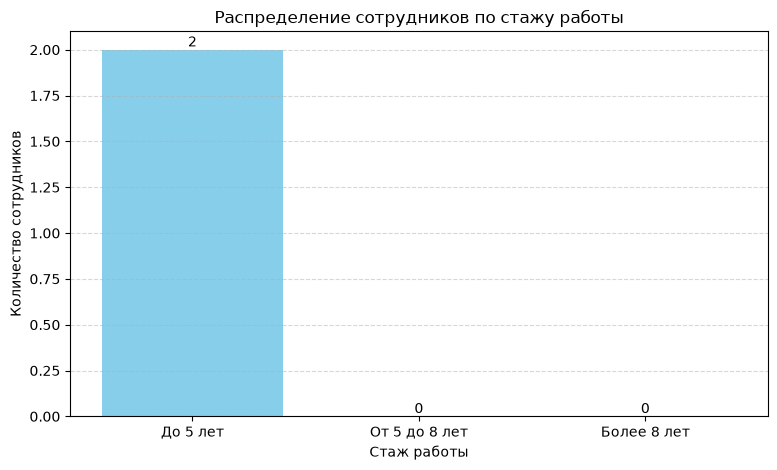

In [14]:
categories = ["До 5 лет", "От 5 до 8 лет", "Более 8 лет"]

counts = [
    sum(1 for x in employees if x < 5),
    sum(1 for x in employees if 5 <= x <= 8),
    sum(1 for x in employees if x > 8)
]

plt.figure(figsize=(9, 5))

plt.bar(categories, counts, color=["skyblue", "orange", "green"])

plt.title("Распределение сотрудников по стажу работы")
plt.xlabel("Стаж работы")
plt.ylabel("Количество сотрудников")

plt.grid(axis="y", linestyle="--", alpha=0.5)

for i, value in enumerate(counts):
    plt.text(i, value, str(value), ha="center", va="bottom")

plt.show()

---
## 7. PyLab6-8 — Расчёты и кластеризация регионов (KMeans, Agglomerative, PCA)
- Репозиторий: https://github.com/RendWanProys/PyLab6-8
- Локальная папка: `PythonWorks/PyLab6-8/`


In [ ]:
use_project("PyLab6-8")


### Файл `PyLab6-8/Math.ipynb`


Стаж: 7.5 лет
Больничный: 2550.00
Рабочие дни: 1912.50
Всего: 4462.50


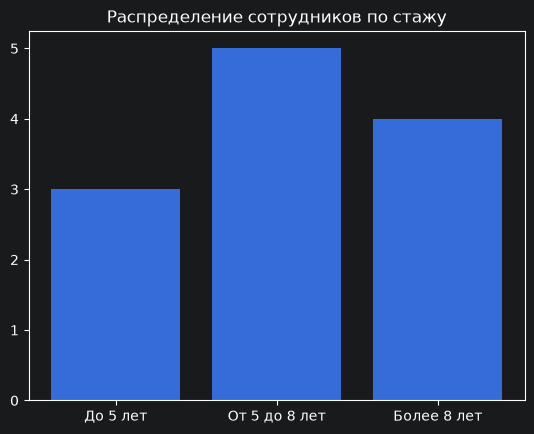

In [1]:
import datetime
import matplotlib.pyplot as plt

date_hired = datetime.date(2019, 5, 15)
date_current = datetime.date.today()

experience_years = (date_current - date_hired).days / 365.25

if experience_years > 8:
    sick_percentage = 1.00
elif 5 <= experience_years <= 8:
    sick_percentage = 0.80
else:
    sick_percentage = 0.50

salaries = [5000, 4500, 6000, 4900]
avg_monthly_salary = sum(salaries) / len(salaries)

total_working_days = 24
sick_days = 15
actual_working_days = total_working_days - sick_days

daily_rate = avg_monthly_salary / total_working_days

sick_leave_pay = sick_days * daily_rate * sick_percentage
working_days_pay = actual_working_days * daily_rate
total_calculated = sick_leave_pay + working_days_pay

print(f"Стаж: {experience_years:.1f} лет")
print(f"Больничный: {sick_leave_pay:.2f}")
print(f"Рабочие дни: {working_days_pay:.2f}")
print(f"Всего: {total_calculated:.2f}")

categories = ['До 5 лет', 'От 5 до 8 лет', 'Более 8 лет']
employee_counts = [3, 5, 4]

plt.bar(categories, employee_counts)
plt.title('Распределение сотрудников по стажу')
plt.show()


### Файл `PyLab6-8/Lab8_v4.ipynb`


In [83]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
df = pd.read_csv(
    "data.csv",
    header=None,
    encoding="1251",
    dtype=str
)

print(df.head())
print("Размер таблицы:", df.shape)


                               0            1                                                  2                                                  3  \
0                            NaN          NaN  11241000300120200001 Доля домашних хозяйств, и...  11241000300120200001 Доля домашних хозяйств, и...   
1                            NaN          NaN                                            2019 г.                                            2020 г.   
2           Российская Федерация          643                                               76,9                                                 80   
3  Центральный федеральный округ          030                                               78,7                                               81,7   
4           Белгородская область  14000000000                                               70,9                                               72,5   

                                                   4                                         

In [84]:
df.columns = [
    "Регион",
    "Код",
    "2019",
    "2020",
    "2021",
    "2022",
    "2023",
    "2024",
    "2025"
]

feature_cols = [
    "2019",
    "2020",
    "2021",
    "2022",
    "2023",
    "2024",
    "2025"
]

for col in feature_cols:
    df[col] = pd.to_numeric(
        df[col].str.replace(",", ".", regex=False),
        errors="coerce"
    )

display(df.head())
print(df.dtypes)

,Регион,Код,2019,2020,2021,2022,2023,2024,2025
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Российская Федерация,643,76.9,80.0,84.0,86.60,87.9,NaN,NaN
3,Центральный федеральный округ,030,78.7,81.7,85.8,87.90,88.5,91.6,93.3
4,Белгородская область,14000000000,70.9,72.5,78.7,78.09,79.2,87.4,91.0


Регион        str
Код           str
2019      float64
2020      float64
2021      float64
2022      float64
2023      float64
2024      float64
2025      float64
dtype: object


In [85]:
print("Количество строк:", len(df))
print("Количество регионов:", df["Регион"].nunique())

print("\nПропущенные значения:")
print(df[feature_cols].isnull().sum())

print("\nСтатистические характеристики:")
display(df[feature_cols].describe())

Количество строк: 100
Количество регионов: 98

Пропущенные значения:
2019    3
2020    3
2021    3
2022    3
2023    3
2024    3
2025    3
dtype: int64

Статистические характеристики:


,2019,2020,2021,2022,2023,2024,2025
count,97.000000,97.000000,97.000000,97.000000,97.000000,97.000000,97.000000
mean,76.302784,79.670825,83.416598,85.755361,87.376907,90.120515,90.749485
std,6.718757,6.407942,5.879164,5.895407,5.378170,4.387837,5.098981
min,64.700000,63.400000,72.000000,73.900000,75.000000,78.090000,72.200000
25%,71.090000,75.700000,79.200000,82.100000,83.200000,86.900000,86.900000
50%,76.900000,79.000000,82.700000,85.500000,87.600000,89.900000,91.400000
75%,79.500000,83.100000,87.300000,89.700000,91.000000,93.400000,93.700000
max,95.000000,95.400000,98.500000,99.100000,99.000000,99.400000,100.000000


In [87]:
regions = df["Регион"].copy()
X = df[feature_cols].copy()
X = X.fillna(X.median())
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [88]:
# KMeans
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)
labels_kmeans = kmeans.fit_predict(X_scaled)

# иерархическая кластеризация
hierarchical = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)
labels_hierarchical = hierarchical.fit_predict(X_scaled)

# DBSCAN
dbscan = DBSCAN(
    eps=1.0,
    min_samples=3
)
labels_dbscan = dbscan.fit_predict(X_scaled)

print("KMeans:", np.unique(labels_kmeans))
print("Agglomerative:", np.unique(labels_hierarchical))
print("DBSCAN:", np.unique(labels_dbscan))

KMeans: [0 1 2]
Agglomerative: [0 1 2]
DBSCAN: [-1  0  1  2]


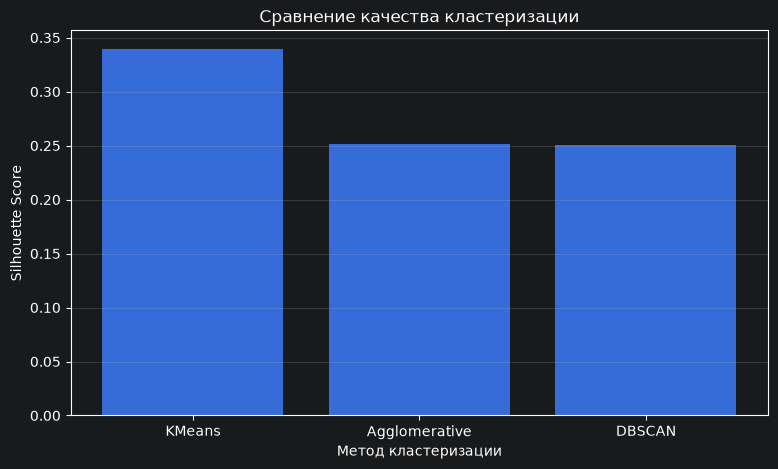

In [66]:
plot_data = results.dropna(subset=["Silhouette"])

plt.figure(figsize=(9, 5))

plt.bar(
    plot_data["Метод"],
    plot_data["Silhouette"]
)

plt.title("Сравнение качества кластеризации")
plt.xlabel("Метод кластеризации")
plt.ylabel("Score")
plt.grid(axis="y", alpha=0.3)

plt.show()

Объяснённая дисперсия: 87.53 %


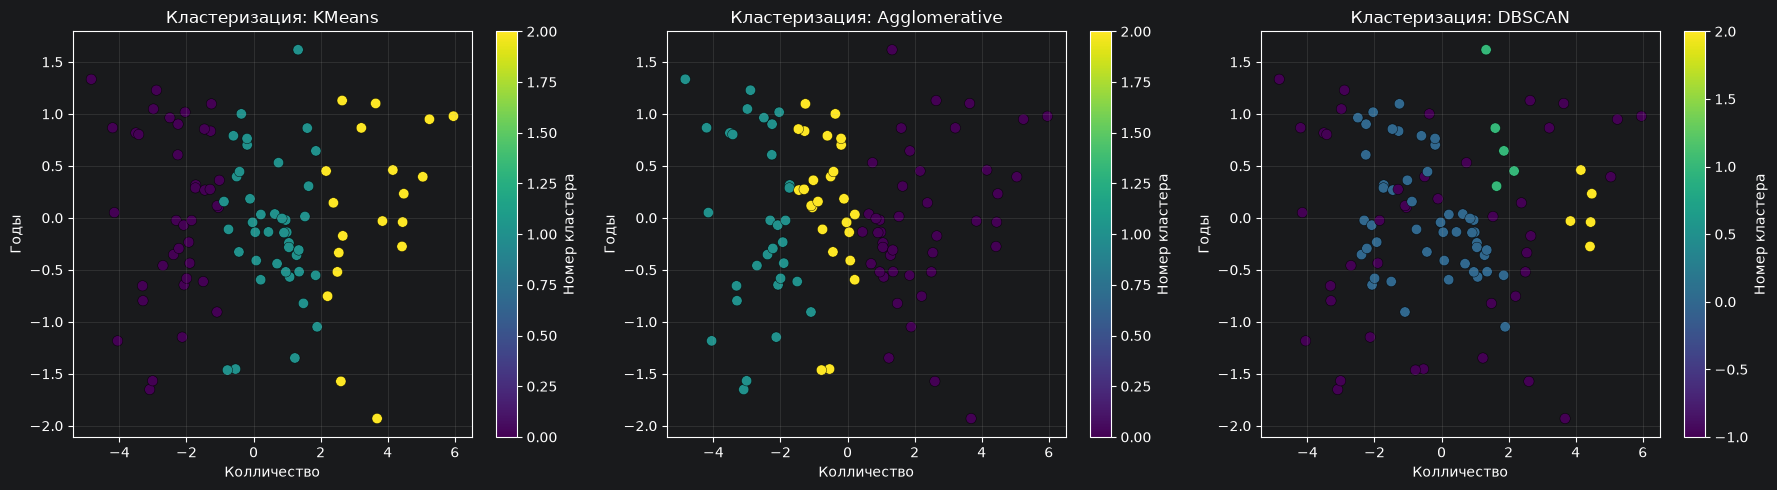

In [90]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print(
    "Объяснённая дисперсия:",
    round(sum(pca.explained_variance_ratio_) * 100, 2),
    "%"
)

models = {
    "KMeans": labels_kmeans,
    "Agglomerative": labels_hierarchical,
    "DBSCAN": labels_dbscan
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, labels) in zip(axes, models.items()):
    scatter = ax.scatter(
        X_pca[:, 0],
        X_pca[:, 1],
        c=labels,
        cmap="viridis",
        s=55,
        edgecolors="black",
        linewidths=0.3
    )

    ax.set_title(f"Кластеризация: {name}")
    ax.set_xlabel("Колличество")
    ax.set_ylabel("Годы")
    ax.grid(alpha=0.2)

    fig.colorbar(scatter, ax=ax, label="Номер кластера")

plt.tight_layout()
plt.show()

---
## 8. py7-8 — Доставка Olist (data/olist_*.csv) и классификация heart.csv
- Репозиторий: https://github.com/RendWanProys/py7-8
- Локальная папка: `PythonWorks/py7-8/`


In [ ]:
use_project("py7-8")


### Файл `py7-8/py7.ipynb`


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

sns.set_theme(style='whitegrid')


In [2]:
orders = pd.read_csv('data/olist_orders_dataset.csv')
items = pd.read_csv('data/olist_order_items_dataset.csv')
products = pd.read_csv('data/olist_products_dataset.csv')
customers = pd.read_csv('data/olist_customers_dataset.csv')
sellers = pd.read_csv('data/olist_sellers_dataset.csv')
payments = pd.read_csv('data/olist_order_payments_dataset.csv')

orders = orders[(orders['order_status'] == 'delivered') & orders['order_delivered_customer_date'].notnull()].copy()

orders['purchase_time'] = pd.to_datetime(orders['order_purchase_timestamp'])
orders['delivery_time'] = pd.to_datetime(orders['order_delivered_customer_date'])
orders['approved_time'] = pd.to_datetime(orders['order_approved_at'])

orders['delivery_days'] = (orders['delivery_time'] - orders['purchase_time']).dt.total_seconds() / 86400.0
orders = orders[(orders['delivery_days'] >= 0.5) & (orders['delivery_days'] <= 60.0)].copy()

orders[['order_id', 'delivery_days']].head()


,order_id,delivery_days
0,e481f51cbdc54678b7cc49136f2d6af7,8.436574
1,53cdb2fc8bc7dce0b6741e2150273451,13.782037
2,47770eb9100c2d0c44946d9cf07ec65d,9.394213
3,949d5b44dbf5de918fe9c16f97b45f8a,13.208750
4,ad21c59c0840e6cb83a9ceb5573f8159,2.873877


In [3]:
products['volume_cm3'] = products['product_length_cm'] * products['product_height_cm'] * products['product_width_cm']
items_p = items.merge(products, on='product_id', how='left')

order_items = items_p.groupby('order_id').agg(
    items_count=('order_item_id', 'count'),
    price=('price', 'sum'),
    freight=('freight_value', 'sum'),
    weight_g=('product_weight_g', 'sum'),
    volume_cm3=('volume_cm3', 'sum'),
    seller_id=('seller_id', 'first')
).reset_index()

pay_agg = payments.groupby('order_id').agg(
    installments=('payment_installments', 'max')
).reset_index()

df = orders.merge(order_items, on='order_id', how='inner')
df = df.merge(pay_agg, on='order_id', how='left')
df = df.merge(customers[['customer_id', 'customer_state']], on='customer_id', how='left')
df = df.merge(sellers[['seller_id', 'seller_state']], on='seller_id', how='left')

df['approval_hours'] = (df['approved_time'] - df['purchase_time']).dt.total_seconds() / 3600.0
df['approval_hours'] = df['approval_hours'].fillna(df['approval_hours'].median()).clip(0, 168)

df['weight_kg'] = df['weight_g'].fillna(df['weight_g'].median()) / 1000.0
df['volume_dm3'] = df['volume_cm3'].fillna(df['volume_cm3'].median()) / 1000.0
df['installments'] = df['installments'].fillna(1)
df['same_state'] = (df['customer_state'] == df['seller_state']).astype(int)

df['hour'] = df['purchase_time'].dt.hour
df['weekday'] = df['purchase_time'].dt.day_of_week
df['month'] = df['purchase_time'].dt.month

features = ['freight', 'price', 'weight_kg', 'volume_dm3', 'items_count', 'same_state', 'approval_hours', 'installments', 'hour', 'weekday', 'month']
df[['delivery_days'] + features].head()


,delivery_days,freight,price,weight_kg,volume_dm3,items_count,same_state,approval_hours,installments,hour,weekday,month
0,8.436574,8.72,29.99,0.50,1.976,1,1,0.178333,1.0,10,0,10
1,13.782037,22.76,118.70,0.40,4.693,1,0,30.713889,1.0,20,1,7
2,9.394213,19.22,159.90,0.42,9.576,1,0,0.276111,3.0,8,2,8
3,13.208750,27.20,45.00,0.45,6.000,1,0,0.298056,1.0,19,5,11
4,2.873877,8.72,19.90,0.25,11.475,1,1,1.030556,1.0,21,1,2


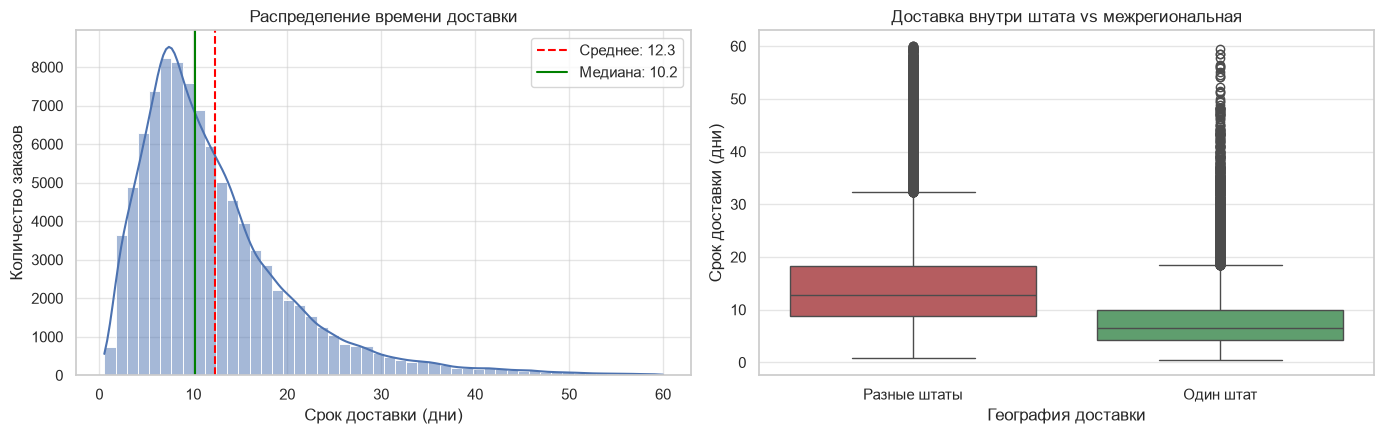

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.histplot(df['delivery_days'], kde=True, bins=50, ax=axes[0], color='#4C72B0')
axes[0].axvline(df['delivery_days'].mean(), color='red', linestyle='--', label=f"Среднее: {df['delivery_days'].mean():.1f}")
axes[0].axvline(df['delivery_days'].median(), color='green', label=f"Медиана: {df['delivery_days'].median():.1f}")
axes[0].set_xlabel('Срок доставки (дни)')
axes[0].set_ylabel('Количество заказов')
axes[0].set_title('Распределение времени доставки')
axes[0].legend()

sns.boxplot(data=df, x='same_state', y='delivery_days', ax=axes[1], hue='same_state', palette=['#C44E52', '#55A868'], legend=False)
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['Разные штаты', 'Один штат'])
axes[1].set_xlabel('География доставки')
axes[1].set_ylabel('Срок доставки (дни)')
axes[1].set_title('Доставка внутри штата vs межрегиональная')

plt.tight_layout()
plt.show()


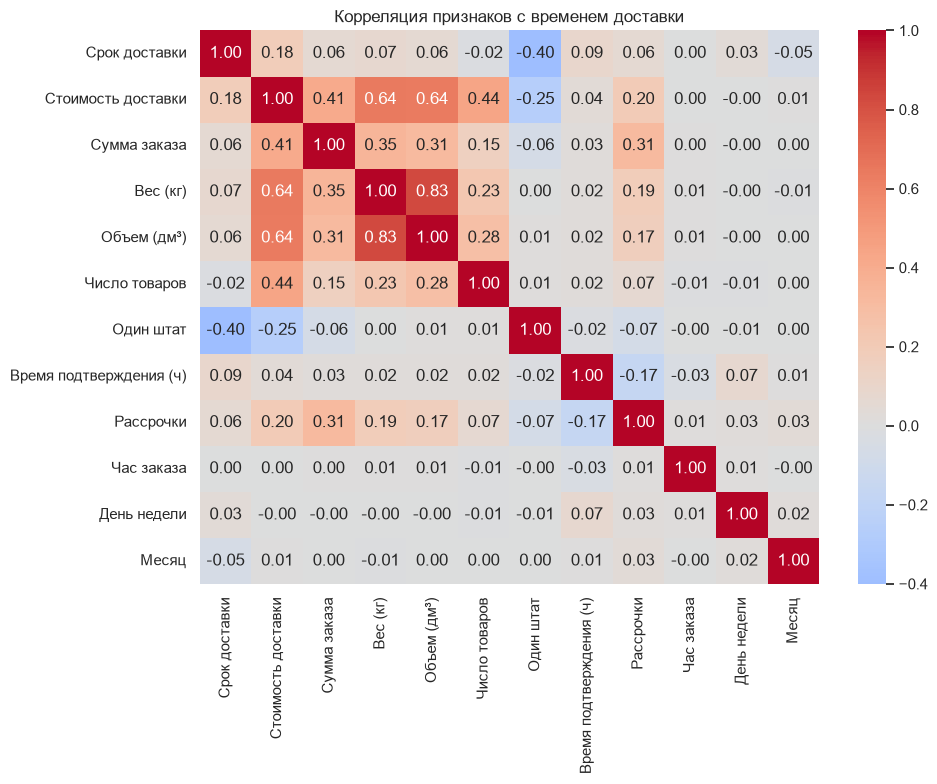

Обучающая выборка: 76931 Тестовая выборка: 19233


In [6]:
feature_names_ru = [
    'Срок доставки', 'Стоимость доставки', 'Сумма заказа', 'Вес (кг)',
    'Объем (дм³)', 'Число товаров', 'Один штат', 'Время подтверждения (ч)',
    'Рассрочки', 'Час заказа', 'День недели', 'Месяц'
]

corr_matrix = df[['delivery_days'] + features].corr()
corr_matrix.columns = feature_names_ru
corr_matrix.index = feature_names_ru

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Корреляция признаков с временем доставки')
plt.tight_layout()
plt.show()

X = df[features]
y = df['delivery_days']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

print('Обучающая выборка:', X_train.shape[0], 'Тестовая выборка:', X_test.shape[0])


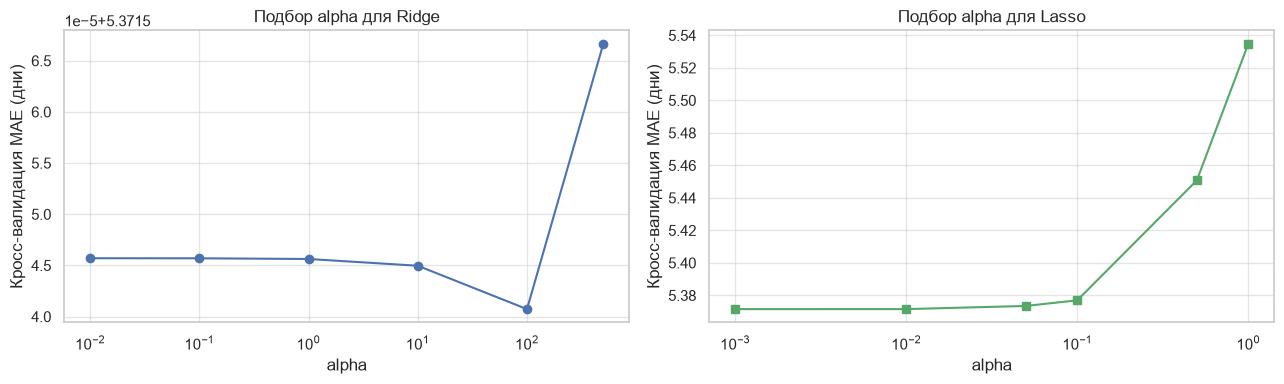

Лучший alpha для Ridge: 100.0 | MAE: 5.3715
Лучший alpha для Lasso: 0.001 | MAE: 5.3715


In [7]:
alphas = [0.01, 0.1, 1.0, 10.0, 100.0, 500.0]
kf = KFold(n_splits=5, shuffle=True, random_state=42)

ridge_scores = []
for a in alphas:
    m = Ridge(alpha=a)
    score = -cross_val_score(m, X_train_sc, y_train, scoring='neg_mean_absolute_error', cv=kf, n_jobs=-1).mean()
    ridge_scores.append(score)

lasso_alphas = [0.001, 0.01, 0.05, 0.1, 0.5, 1.0]
lasso_scores = []
for a in lasso_alphas:
    m = Lasso(alpha=a, max_iter=1000, tol=1e-3, random_state=42)
    score = -cross_val_score(m, X_train_sc, y_train, scoring='neg_mean_absolute_error', cv=kf, n_jobs=-1).mean()
    lasso_scores.append(score)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(alphas, ridge_scores, marker='o', color='#4C72B0')
axes[0].set_xscale('log')
axes[0].set_title('Подбор alpha для Ridge')
axes[0].set_xlabel('alpha')
axes[0].set_ylabel('Кросс-валидация MAE (дни)')
axes[0].grid(True)

axes[1].plot(lasso_alphas, lasso_scores, marker='s', color='#55A868')
axes[1].set_xscale('log')
axes[1].set_title('Подбор alpha для Lasso')
axes[1].set_xlabel('alpha')
axes[1].set_ylabel('Кросс-валидация MAE (дни)')
axes[1].grid(True)

plt.tight_layout()
plt.show()

best_ridge_alpha = alphas[ridge_scores.index(min(ridge_scores))]
best_lasso_alpha = lasso_alphas[lasso_scores.index(min(lasso_scores))]
print('Лучший alpha для Ridge:', best_ridge_alpha, '| MAE:', round(min(ridge_scores), 4))
print('Лучший alpha для Lasso:', best_lasso_alpha, '| MAE:', round(min(lasso_scores), 4))


,Модель,MAE,RMSE,R2
0,Линейная регрессия,5.425580,7.695834,0.179392
1,Ridge (alpha=100.0),5.425637,7.695855,0.179388
2,Lasso (alpha=0.001),5.425558,7.695793,0.179401


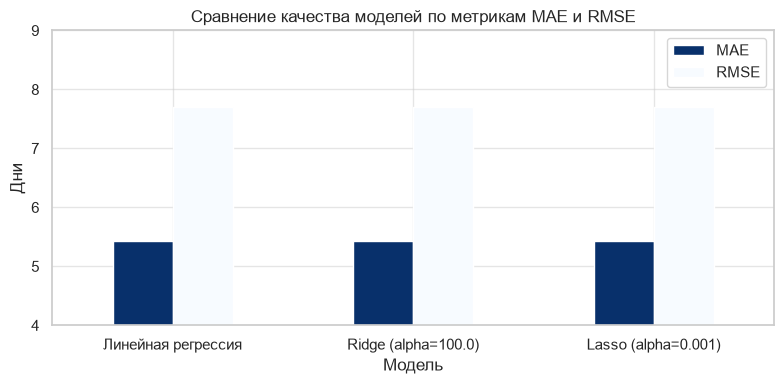

In [9]:
models = {
    'Линейная регрессия': LinearRegression(),
    f'Ridge (alpha={best_ridge_alpha})': Ridge(alpha=best_ridge_alpha),
    f'Lasso (alpha={best_lasso_alpha})': Lasso(alpha=best_lasso_alpha, max_iter=1000, tol=1e-3, random_state=42)
}

res = []
for name, m in models.items():
    m.fit(X_train_sc, y_train)
    y_pred = m.predict(X_test_sc)
    res.append({
        'Модель': name,
        'MAE': mean_absolute_error(y_test, y_pred),
        'RMSE': root_mean_squared_error(y_test, y_pred),
        'R2': r2_score(y_test, y_pred)
    })

res_df = pd.DataFrame(res)
display(res_df)

fig, ax = plt.subplots(figsize=(8, 4))
res_df.plot(x='Модель', y=['MAE', 'RMSE'], kind='bar', ax=ax, colormap='Blues_r')
ax.set_ylabel('Дни')
ax.set_title('Сравнение качества моделей по метрикам MAE и RMSE')
ax.set_xticklabels(res_df['Модель'], rotation=0)
ax.set_ylim(4, 9)
plt.tight_layout()
plt.show()


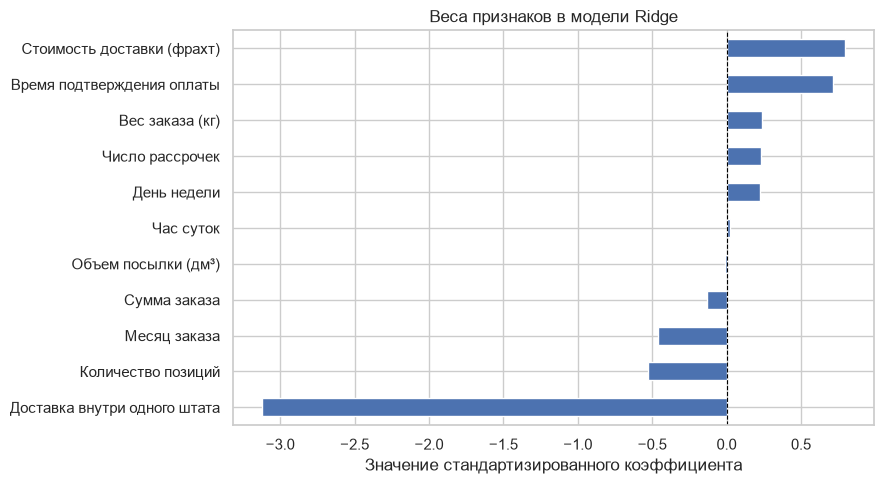

In [8]:
best_model = models[f'Ridge (alpha={best_ridge_alpha})']

labels_dict = {
    'same_state': 'Доставка внутри одного штата',
    'freight': 'Стоимость доставки (фрахт)',
    'approval_hours': 'Время подтверждения оплаты',
    'weight_kg': 'Вес заказа (кг)',
    'volume_dm3': 'Объем посылки (дм³)',
    'month': 'Месяц заказа',
    'price': 'Сумма заказа',
    'installments': 'Число рассрочек',
    'weekday': 'День недели',
    'items_count': 'Количество позиций',
    'hour': 'Час суток'
}

coef_series = pd.Series(best_model.coef_, index=[labels_dict[f] for f in features]).sort_values()

plt.figure(figsize=(9, 5))
coef_series.plot(kind='barh', color='#4C72B0')
plt.axvline(0, color='black', linestyle='--', linewidth=0.8)
plt.title('Веса признаков в модели Ridge')
plt.xlabel('Значение стандартизированного коэффициента')
plt.tight_layout()
plt.show()


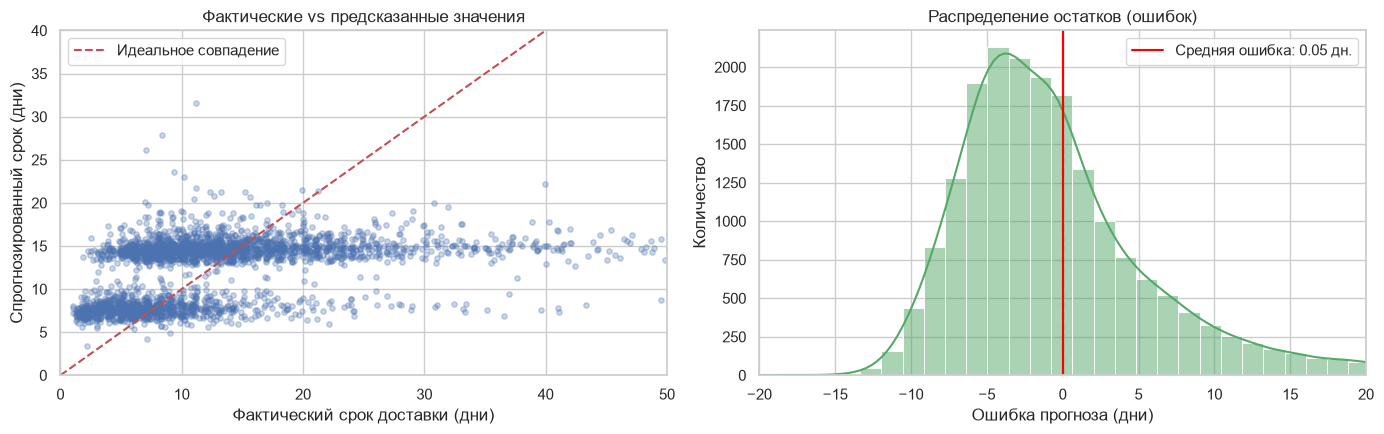

,Фактический срок,Прогноз,Ошибка
0,20.01,14.74,5.28
1,11.01,13.41,-2.40
2,6.21,8.39,-2.19
3,11.12,13.75,-2.63
4,8.87,13.93,-5.06
5,10.27,15.61,-5.35
6,12.81,18.71,-5.90
7,8.01,8.37,-0.36
8,9.04,15.89,-6.85
9,4.41,7.76,-3.35


In [9]:
y_pred_best = best_model.predict(X_test_sc)
res = y_test - y_pred_best

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sample_idx = np.random.choice(len(y_test), 3000, replace=False)
axes[0].scatter(y_test.values[sample_idx], y_pred_best[sample_idx], alpha=0.3, s=15, color='#4C72B0')
axes[0].plot([0, 50], [0, 50], 'r--', label='Идеальное совпадение')
axes[0].set_xlim(0, 50)
axes[0].set_ylim(0, 40)
axes[0].set_xlabel('Фактический срок доставки (дни)')
axes[0].set_ylabel('Спрогнозированный срок (дни)')
axes[0].set_title('Фактические vs предсказанные значения')
axes[0].legend()

sns.histplot(res, kde=True, bins=50, ax=axes[1], color='#55A868')
axes[1].axvline(0, color='black', linestyle='--')
axes[1].axvline(res.mean(), color='red', label=f"Средняя ошибка: {res.mean():.2f} дн.")
axes[1].set_xlim(-20, 20)
axes[1].set_xlabel('Ошибка прогноза (дни)')
axes[1].set_ylabel('Количество')
axes[1].set_title('Распределение остатков (ошибок)')
axes[1].legend()

plt.tight_layout()
plt.show()

pred_sample = pd.DataFrame({
    'Фактический срок': y_test.values[:10],
    'Прогноз': y_pred_best[:10],
    'Ошибка': res.values[:10]
})
pred_sample.round(2)


### Файл `py7-8/py8.ipynb`


In [22]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve

In [ ]:
df = pd.read_csv('heart.csv')
df.head()

In [24]:
X = df.drop('target', axis=1)
y = df['target']

num_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
cat_cols = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(drop='first'), cat_cols)
])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

best k: 9 roc-auc: 0.8874458874458875


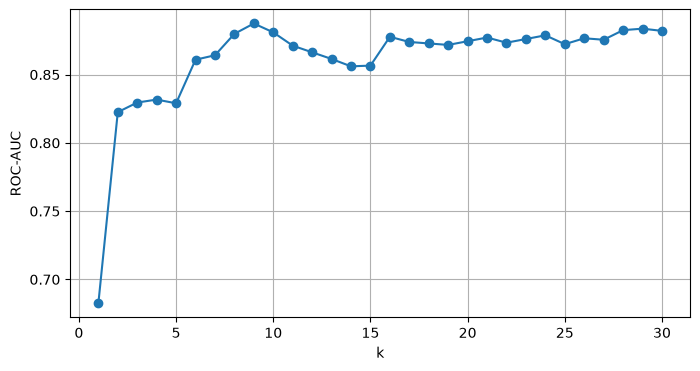

In [25]:
k_range = list(range(1, 31))
auc_scores = []

for k in k_range:
    pipe = Pipeline([
        ('prep', preprocessor),
        ('knn', KNeighborsClassifier(n_neighbors=k))
    ])
    pipe.fit(X_train, y_train)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    auc_scores.append(roc_auc_score(y_test, y_prob))

best_k = k_range[auc_scores.index(max(auc_scores))]
print('best k:', best_k, 'roc-auc:', max(auc_scores))

plt.figure(figsize=(8, 4))
plt.plot(k_range, auc_scores, marker='o')
plt.xlabel('k')
plt.ylabel('ROC-AUC')
plt.grid()
plt.show()

KNN (k=9): Accuracy = 0.803, ROC-AUC = 0.887
SVM: Accuracy = 0.836, ROC-AUC = 0.886
Decision Tree: Accuracy = 0.721, ROC-AUC = 0.720
Random Forest: Accuracy = 0.787, ROC-AUC = 0.871


C:\Users\1\PycharmProjects\PythonProject\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


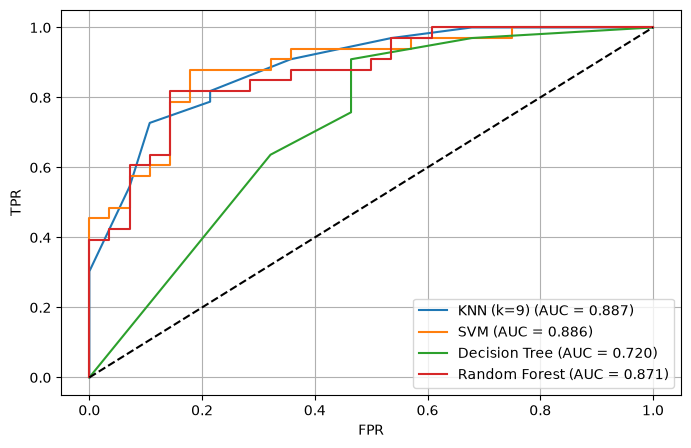

In [27]:
models = {
    f'KNN (k={best_k})': KNeighborsClassifier(n_neighbors=best_k),
    'SVM': SVC(probability=True, kernel='linear', C=0.1),
    'Decision Tree': DecisionTreeClassifier(max_depth=3, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=4, random_state=42)
}

plt.figure(figsize=(8, 5))

for name, model in models.items():
    pipe = Pipeline([
        ('prep', preprocessor),
        ('model', model)
    ])
    pipe.fit(X_train, y_train)
    
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    
    acc = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)
    print(f'{name}: Accuracy = {acc:.3f}, ROC-AUC = {auc:.3f}')
    
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.legend()
plt.grid()
plt.show()

### Файл `py7-8/task10.py`


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# 1. Загрузка данных
df = pd.read_csv('heart.csv')

X = df.drop('target', axis=1)
y = df['target']

num_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
cat_cols = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(drop='first'), cat_cols),
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 2. Подбор k для KNN
k_range = list(range(1, 31))
auc_scores = []

for k in k_range:
  pipe = Pipeline(
      [('prep', preprocessor), ('knn', KNeighborsClassifier(n_neighbors=k))]
  )
  pipe.fit(X_train, y_train)
  y_prob = pipe.predict_proba(X_test)[:, 1]
  auc_scores.append(roc_auc_score(y_test, y_prob))

best_k = k_range[auc_scores.index(max(auc_scores))]
print('best k:', best_k, 'roc-auc:', max(auc_scores))

plt.figure(figsize=(8, 4))
plt.plot(k_range, auc_scores, marker='o')
plt.xlabel('k')
plt.ylabel('ROC-AUC')
plt.grid()
plt.show()

# 3. Сравнение 4 моделей
models = {
    f'KNN (k={best_k})': KNeighborsClassifier(n_neighbors=best_k),
    'SVM': SVC(probability=True, kernel='linear', C=0.1),
    'Decision Tree': DecisionTreeClassifier(max_depth=3, random_state=42),
    'Random Forest': RandomForestClassifier(
        n_estimators=100, max_depth=4, random_state=42
    ),
}

plt.figure(figsize=(8, 5))

for name, model in models.items():
  pipe = Pipeline([('prep', preprocessor), ('model', model)])
  pipe.fit(X_train, y_train)

  y_pred = pipe.predict(X_test)
  y_prob = pipe.predict_proba(X_test)[:, 1]

  acc = accuracy_score(y_test, y_pred)
  auc = roc_auc_score(y_test, y_prob)
  print(f'{name}: Accuracy = {acc:.3f}, ROC-AUC = {auc:.3f}')

  fpr, tpr, _ = roc_curve(y_test, y_prob)
  plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.legend()
plt.grid()
plt.show()


### Файл `py7-8/main.py`


In [ ]:
# This is a sample Python script.

# Press Shift+F10 to execute it or replace it with your code.
# Press Double Shift to search everywhere for classes, files, tool windows, actions, and settings.


def print_hi(name):
    # Use a breakpoint in the code line below to debug your script.
    print(f'Hi, {name}')  # Press Ctrl+F8 to toggle the breakpoint.


# Press the green button in the gutter to run the script.
if __name__ == '__main__':
    print_hi('PyCharm')

# See PyCharm help at https://www.jetbrains.com/help/pycharm/
